# PP test

The 596 single-event posteriors are precomputed; we compute the credible level of the truth for each event and the Kolmogorov-Smirnov calibration, and provide the same computation for your own scored grids.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT/'src')); sys.path.insert(0, str(ROOT/'examples'))
import numpy as np, matplotlib.pyplot as plt
from scipy.stats import kstest
from exmarg import figstyle; figstyle.apply()
get_ipython().run_line_magic("matplotlib","inline")

/projects/standard/vuk/shared/boyb001/non_gaussian/exmarg/src/exmarg/profiles.py:14: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


## Compute the credible level of the truth for every event

Midpoint-CDF of each 1-D marginal, evaluated at the injected value.


In [2]:
Z = np.load('data/pp_posteriors.npz')
axes = {'mc': Z['mc_ax'], 'q': Z['q_ax'], 'x': Z['x_ax']}
marg = {'mc': Z['m_mc'], 'q': Z['m_q'], 'x': Z['m_x']}
truth = Z['truth']
def credible_levels(m, ax, tr):
    cdf = (np.cumsum(m, 1) - 0.5*m) / m.sum(1, keepdims=True)
    return np.array([np.interp(tr[i], ax, cdf[i]) for i in range(len(tr))])
q = np.stack([credible_levels(marg[k], axes[k], truth[:, j])
              for j, k in enumerate(['mc','q','x'])], axis=1)
print('%d events; KS p:' % len(q),
      {n: round(kstest(q[:, i], 'uniform').pvalue, 3)
       for i, n in enumerate(['Mc','q','chi'])})

596 events; KS p: {'Mc': np.float64(0.719), 'q': np.float64(0.941), 'chi': np.float64(0.478)}


## The PP figure (Figure 10)

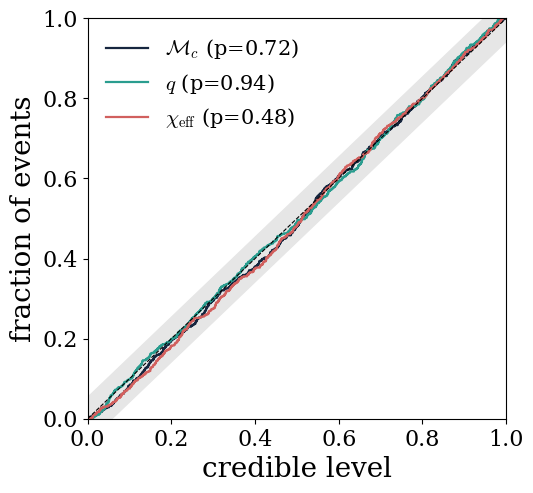

In [3]:
names=[r'$\mathcal{M}_c$',r'$q$',r'$\chi_{\rm eff}$']
cols=[figstyle.NAVY,'#2a9d8f',figstyle.RED]; n=len(q); eps=1.36/np.sqrt(n)
g=np.linspace(0,1,200); fig,ax=plt.subplots(figsize=(5.4,5.2))
ax.fill_between(g,np.clip(g-eps,0,1),np.clip(g+eps,0,1),color='0.9')
for i in range(3):
    x=np.sort(q[:,i]); y=np.arange(1,n+1)/n
    ax.step(x,y,where='post',color=cols[i],lw=1.6,
            label='%s (p=%.2g)'%(names[i],kstest(q[:,i],'uniform').pvalue))
ax.plot([0,1],[0,1],'k--',lw=0.8); ax.set_xlim(0,1); ax.set_ylim(0,1)
ax.set_xlabel('credible level'); ax.set_ylabel('fraction of events')
ax.legend(frameon=False,fontsize=figstyle.FS_LEGEND); plt.show()

## Custom Injections

Score a set of injections with `scripts/run_pp_pe.py`, then compute the same credible levels straight from the grid posteriors:

In [4]:
def credible_from_grid(grid_files):
    out=[]
    for f in grid_files:
        z=np.load(f); P=np.exp(z['lnL']-z['lnL'].max()); row=[]
        for i,(a,t) in enumerate([('mc_ax','truth_Mc'),('q_ax','truth_q'),('x_ax','truth_x')]):
            m=P.sum(axis=tuple(k for k in range(3) if k!=i))
            cdf=(np.cumsum(m)-0.5*m)/m.sum(); row.append(float(np.interp(float(z[t]),z[a],cdf)))
        out.append(row)
    return np.array(out)
print('credible_from_grid ready for your run_pp_pe.py outputs')

credible_from_grid ready for your run_pp_pe.py outputs
